# Ejercicio 1. Creación de matrices y aplicación de filtros de media y mediana

In [38]:
# Crear nuevamente las matrices del Ejercicio 1
imagen_1_ej1 = np.full((7, 7), 100, dtype=np.uint8)
imagen_2_ej1 = np.full((8, 8), 100, dtype=np.uint8)

# Aplicar filtro de media 3x3
media_1_ej1 = cv2.blur(imagen_1_ej1, (3, 3))
media_2_ej1 = cv2.blur(imagen_2_ej1, (3, 3))

# Mostrar dimensiones y resultados
print("Dimensiones:", media_1_ej1.shape)
print(media_1_ej1)

print("\nDimensiones:", media_2_ej1.shape)
print(media_2_ej1)

Dimensiones: (7, 7)
[[100 100 100 100 100 100 100]
 [100 100 100 100 100 100 100]
 [100 100 100 100 100 100 100]
 [100 100 100 100 100 100 100]
 [100 100 100 100 100 100 100]
 [100 100 100 100 100 100 100]
 [100 100 100 100 100 100 100]]

Dimensiones: (8, 8)
[[100 100 100 100 100 100 100 100]
 [100 100 100 100 100 100 100 100]
 [100 100 100 100 100 100 100 100]
 [100 100 100 100 100 100 100 100]
 [100 100 100 100 100 100 100 100]
 [100 100 100 100 100 100 100 100]
 [100 100 100 100 100 100 100 100]
 [100 100 100 100 100 100 100 100]]


In [39]:
# Aplicar filtro de mediana 3x3
mediana_1_ej1 = cv2.medianBlur(imagen_1_ej1, 3)
mediana_2_ej1 = cv2.medianBlur(imagen_2_ej1, 3)

# Mostrar resultados
print("Mediana 3x3 - Imagen 7x7:")
print(mediana_1_ej1)

print("\nMediana 3x3 - Imagen 8x8:")
print(mediana_2_ej1)

Mediana 3x3 - Imagen 7x7:
[[100 100 100 100 100 100 100]
 [100 100 100 100 100 100 100]
 [100 100 100 100 100 100 100]
 [100 100 100 100 100 100 100]
 [100 100 100 100 100 100 100]
 [100 100 100 100 100 100 100]
 [100 100 100 100 100 100 100]]

Mediana 3x3 - Imagen 8x8:
[[100 100 100 100 100 100 100 100]
 [100 100 100 100 100 100 100 100]
 [100 100 100 100 100 100 100 100]
 [100 100 100 100 100 100 100 100]
 [100 100 100 100 100 100 100 100]
 [100 100 100 100 100 100 100 100]
 [100 100 100 100 100 100 100 100]
 [100 100 100 100 100 100 100 100]]


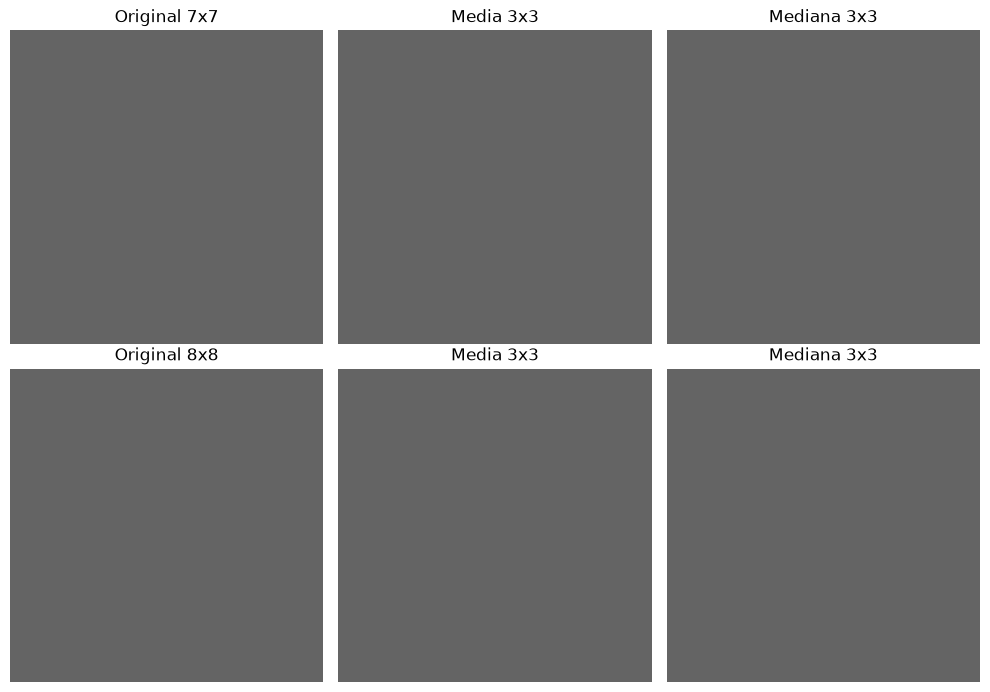

In [40]:
fig, ejes = plt.subplots(2, 3, figsize=(10, 7))

imagenes_ej1 = [
    (imagen_1_ej1, "Original 7x7"),
    (media_1_ej1, "Media 3x3"),
    (mediana_1_ej1, "Mediana 3x3"),
    (imagen_2_ej1, "Original 8x8"),
    (media_2_ej1, "Media 3x3"),
    (mediana_2_ej1, "Mediana 3x3")
]

for eje, (imagen, titulo) in zip(ejes.flat, imagenes_ej1):
    eje.imshow(imagen, cmap="gray", vmin=0, vmax=255)
    eje.set_title(titulo)
    eje.axis("off")

plt.tight_layout()

plt.savefig(
    "resultados/ejercicio_1/ejercicio_1_resultados.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Ejercicio 2. Aplicación de filtros de suavizado y realce

**Objetivo:** Generar dos imágenes matriciales y aplicar un filtro de media 3×3 para suavizar y una máscara de realce para resaltar los cambios de intensidad.

In [5]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

# Primera imagen: matriz de 12 x 12
imagen_1 = np.array([
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 100, 100, 100, 100, 100, 100, 0, 0, 0],
    [0, 0, 0, 100, 200, 200, 200, 200, 100, 0, 0, 0],
    [0, 0, 0, 100, 200, 200, 200, 200, 100, 0, 0, 0],
    [0, 0, 0, 100, 200, 200, 200, 200, 100, 0, 0, 0],
    [0, 0, 0, 100, 200, 200, 200, 200, 100, 0, 0, 0],
    [0, 0, 0, 100, 100, 100, 100, 100, 100, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
], dtype=np.uint8)

# Segunda imagen: matriz de 12 x 12
imagen_2 = np.array([
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 50, 50, 50, 50, 50, 50, 50, 50, 50, 50, 0],
    [0, 50, 100, 100, 100, 100, 100, 100, 100, 100, 50, 0],
    [0, 50, 100, 150, 150, 150, 150, 150, 150, 100, 50, 0],
    [0, 50, 100, 150, 200, 200, 200, 200, 150, 100, 50, 0],
    [0, 50, 100, 150, 200, 255, 255, 200, 150, 100, 50, 0],
    [0, 50, 100, 150, 200, 200, 200, 200, 150, 100, 50, 0],
    [0, 50, 100, 150, 150, 150, 150, 150, 150, 100, 50, 0],
    [0, 50, 100, 100, 100, 100, 100, 100, 100, 100, 50, 0],
    [0, 50, 100, 100, 100, 100, 100, 100, 100, 100, 50, 0],
    [0, 50, 50, 50, 50, 50, 50, 50, 50, 50, 50, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
], dtype=np.uint8)

print("Primera imagen:")
print(imagen_1)

print("\nSegunda imagen:")
print(imagen_2)

Primera imagen:
[[  0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0 100 100 100 100 100 100   0   0   0]
 [  0   0   0 100 200 200 200 200 100   0   0   0]
 [  0   0   0 100 200 200 200 200 100   0   0   0]
 [  0   0   0 100 200 200 200 200 100   0   0   0]
 [  0   0   0 100 200 200 200 200 100   0   0   0]
 [  0   0   0 100 100 100 100 100 100   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0]]

Segunda imagen:
[[  0   0   0   0   0   0   0   0   0   0   0   0]
 [  0  50  50  50  50  50  50  50  50  50  50   0]
 [  0  50 100 100 100 100 100 100 100 100  50   0]
 [  0  50 100 150 150 150 150 150 150 100  50   0]
 [  0  50 100 150 200 200 200 200 150 100  50   0]
 [  0  50 100 150 200 255 255 200 150 100  50   0]
 [  0  50 100 150 200 200 200 200 150 100  50   

In [6]:
# Aplicar filtro de media 3x3
suavizada_1 = cv2.blur(imagen_1, (3, 3))
suavizada_2 = cv2.blur(imagen_2, (3, 3))

# Mostrar los resultados
print("Imagen 1 suavizada:")
print(suavizada_1)

print("\nImagen 2 suavizada:")
print(suavizada_2)

Imagen 1 suavizada:
[[  0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0  11  22  33  33  33  33  22  11   0   0]
 [  0   0  22  56  89 100 100  89  56  22   0   0]
 [  0   0  33  89 144 167 167 144  89  33   0   0]
 [  0   0  33 100 167 200 200 167 100  33   0   0]
 [  0   0  33 100 167 200 200 167 100  33   0   0]
 [  0   0  33  89 144 167 167 144  89  33   0   0]
 [  0   0  22  56  89 100 100  89  56  22   0   0]
 [  0   0  11  22  33  33  33  33  22  11   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0]]

Imagen 2 suavizada:
[[ 22  22  33  33  33  33  33  33  33  33  22  22]
 [ 22  28  44  50  50  50  50  50  50  44  28  22]
 [ 33  44  78  94 100 100 100 100  94  78  44  33]
 [ 33  50  94 128 144 150 150 144 128  94  50  33]
 [ 33  50 100 144 178 196 196 178 144 100  50  33]
 [ 33  50 100 150 189 212 212 189 150 100  50  33]
 [ 33  50 100 144 178 196 196 178 144 10

In [7]:
# Definir la máscara de realce 3x3
kernel_realce = np.array([
    [1,  1, 1],
    [1, -8, 1],
    [1,  1, 1]
], dtype=np.float32)

# Aplicar el filtro realzante a las dos imágenes
realce_1 = cv2.filter2D(imagen_1, cv2.CV_32F, kernel_realce)
realce_2 = cv2.filter2D(imagen_2, cv2.CV_32F, kernel_realce)

# Convertir los resultados a valores visibles entre 0 y 255
realce_1_visual = cv2.convertScaleAbs(realce_1)
realce_2_visual = cv2.convertScaleAbs(realce_2)

# Mostrar resultados
print("Imagen 1 realzada:")
print(realce_1)

print("\nImagen 2 realzada:")
print(realce_2)

Imagen 1 realzada:
[[   0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.]
 [   0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.]
 [   0.    0.  100.  200.  300.  300.  300.  300.  200.  100.    0.    0.]
 [   0.    0.  200. -400. -100.    0.    0. -100. -400.  200.    0.    0.]
 [   0.    0.  300. -100. -500. -300. -300. -500. -100.  300.    0.    0.]
 [   0.    0.  300.    0. -300.    0.    0. -300.    0.  300.    0.    0.]
 [   0.    0.  300.    0. -300.    0.    0. -300.    0.  300.    0.    0.]
 [   0.    0.  300. -100. -500. -300. -300. -500. -100.  300.    0.    0.]
 [   0.    0.  200. -400. -100.    0.    0. -100. -400.  200.    0.    0.]
 [   0.    0.  100.  200.  300.  300.  300.  300.  200.  100.    0.    0.]
 [   0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.]
 [   0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.]]

Imagen 2 realzada:
[[ 200.  200.  300.  300.  300.  300.  300.  300.  300.  300

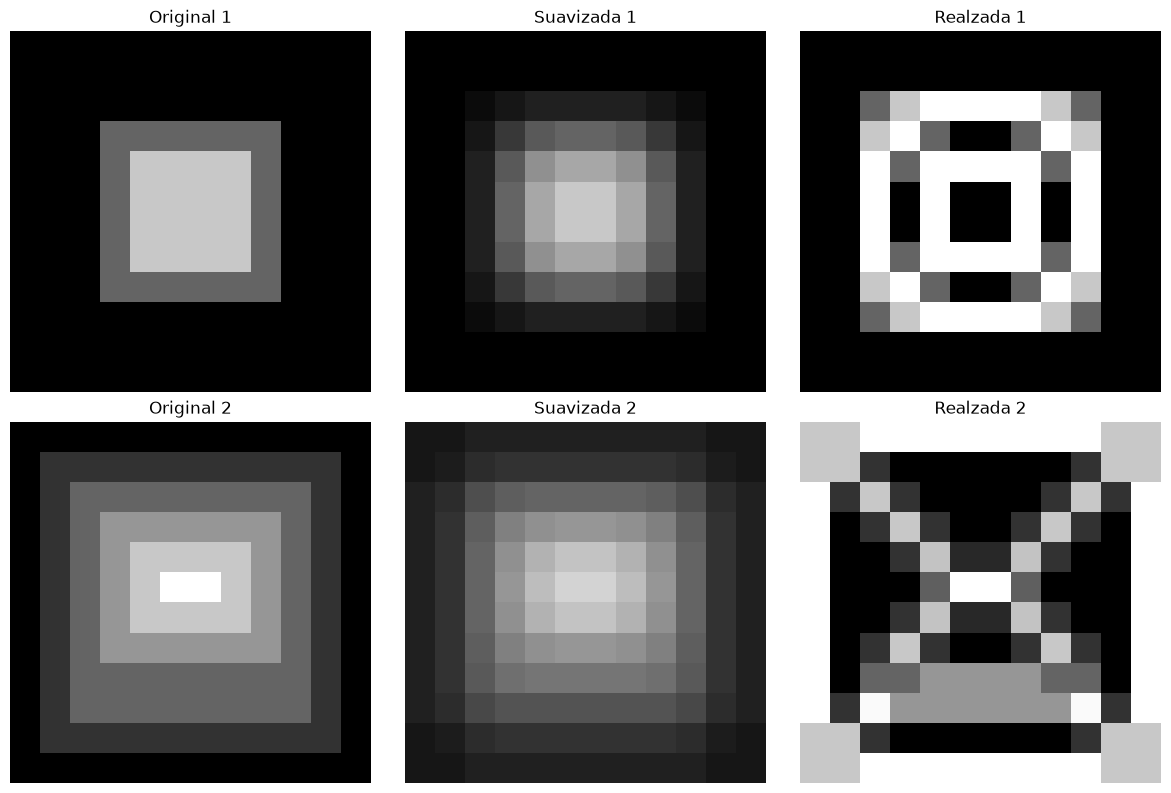

In [8]:
fig, ejes = plt.subplots(2, 3, figsize=(12, 8))

imagenes = [
    (imagen_1, "Original 1"),
    (suavizada_1, "Suavizada 1"),
    (realce_1_visual, "Realzada 1"),
    (imagen_2, "Original 2"),
    (suavizada_2, "Suavizada 2"),
    (realce_2_visual, "Realzada 2")
]

for eje, (imagen, titulo) in zip(ejes.flat, imagenes):
    eje.imshow(imagen, cmap="gray", vmin=0, vmax=255)
    eje.set_title(titulo)
    eje.axis("off")

plt.tight_layout()
plt.savefig("resultados/ejercicio_2/ejercicio_2_resultados.png",
            dpi=300, bbox_inches="tight")
plt.show()

# Ejercicio 3. Aplicación de detectores de bordes

**Objetivo:** Generar dos imágenes matriciales y aplicar los detectores Roberts, vertical, horizontal y Sobel para identificar los cambios de intensidad.

**Fundamento:** Los detectores de bordes permiten identificar los límites entre regiones con diferentes intensidades de píxel.

In [12]:
# Primera imagen: matriz de 10 x 10
imagen_1 = np.array([
    [100,100,100,100,100,100,100,100,100,100],
    [100,100,100,100,100,100,100,100,100,100],
    [100,100,100,200,200,200,200,100,100,100],
    [100,100,100,200,200,200,200,100,100,100],
    [100,100,100,200,200,200,200,100,100,100],
    [100,100,100,200,200,200,200,100,100,100],
    [100,100,100,100,100,100,100,100,100,100],
    [100,100,100,100,100,100,100,100,100,100],
    [100,100,100,100,100,100,100,100,100,100],
    [100,100,100,100,100,100,100,100,100,100]
], dtype=np.uint8)


# Segunda imagen: matriz de 12 x 12
imagen_2 = np.array([
    [0,0,0,0,0,0,0,0,0,0,0,0],
    [0,0,0,0,0,0,0,0,0,0,0,0],
    [0,0,0,0,0,0,0,0,0,0,0,0],
    [0,0,0,100,100,100,100,100,100,0,0,0],
    [0,0,0,100,200,200,200,200,100,0,0,0],
    [0,0,0,100,200,200,200,200,100,0,0,0],
    [0,0,0,100,200,200,200,200,100,0,0,0],
    [0,0,0,100,200,200,200,200,100,0,0,0],
    [0,0,0,100,100,100,100,100,100,0,0,0],
    [0,0,0,0,0,0,0,0,0,0,0,0],
    [0,0,0,0,0,0,0,0,0,0,0,0],
    [0,0,0,0,0,0,0,0,0,0,0,0]
], dtype=np.uint8)


print("Dimensiones de la imagen 1:", imagen_1.shape)
print("Dimensiones de la imagen 2:", imagen_2.shape)

Dimensiones de la imagen 1: (10, 10)
Dimensiones de la imagen 2: (12, 12)


In [13]:
# Máscaras del detector Roberts
roberts_x = np.array([
    [1, 0],
    [0, -1]
], dtype=np.float32)

roberts_y = np.array([
    [0, 1],
    [-1, 0]
], dtype=np.float32)


# Máscara del detector vertical
kernel_vertical = np.array([
    [-1, 0, 1],
    [-1, 0, 1],
    [-1, 0, 1]
], dtype=np.float32)


# Máscara del detector horizontal
kernel_horizontal = np.array([
    [-1, -1, -1],
    [0, 0, 0],
    [1, 1, 1]
], dtype=np.float32)


# Máscaras del detector Sobel
sobel_x = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype=np.float32)

sobel_y = np.array([
    [-1, -2, -1],
    [0, 0, 0],
    [1, 2, 1]
], dtype=np.float32)

In [14]:
print("Máscara Roberts X:")
print(roberts_x)

print("\nMáscara Roberts Y:")
print(roberts_y)

print("\nMáscara vertical:")
print(kernel_vertical)

print("\nMáscara horizontal:")
print(kernel_horizontal)

print("\nMáscara Sobel X:")
print(sobel_x)

print("\nMáscara Sobel Y:")
print(sobel_y)

Máscara Roberts X:
[[ 1.  0.]
 [ 0. -1.]]

Máscara Roberts Y:
[[ 0.  1.]
 [-1.  0.]]

Máscara vertical:
[[-1.  0.  1.]
 [-1.  0.  1.]
 [-1.  0.  1.]]

Máscara horizontal:
[[-1. -1. -1.]
 [ 0.  0.  0.]
 [ 1.  1.  1.]]

Máscara Sobel X:
[[-1.  0.  1.]
 [-2.  0.  2.]
 [-1.  0.  1.]]

Máscara Sobel Y:
[[-1. -2. -1.]
 [ 0.  0.  0.]
 [ 1.  2.  1.]]


In [15]:
def aplicar_detectores(imagen):

    # Detector Roberts: dos respuestas parciales
    roberts_gx = cv2.filter2D(imagen, cv2.CV_32F, roberts_x)
    roberts_gy = cv2.filter2D(imagen, cv2.CV_32F, roberts_y)

    # Máximo de los valores absolutos
    resultado_roberts = np.maximum(
        np.abs(roberts_gx),
        np.abs(roberts_gy)
    )

    # Detector vertical: sin valor absoluto
    resultado_vertical = cv2.filter2D(
        imagen, cv2.CV_32F, kernel_vertical
    )

    # Detector horizontal: con valor absoluto
    resultado_horizontal = np.abs(
        cv2.filter2D(imagen, cv2.CV_32F, kernel_horizontal)
    )

    # Detector Sobel: dos respuestas parciales
    sobel_gx = cv2.filter2D(imagen, cv2.CV_32F, sobel_x)
    sobel_gy = cv2.filter2D(imagen, cv2.CV_32F, sobel_y)

    # Máximo de los valores absolutos
    resultado_sobel = np.maximum(
        np.abs(sobel_gx),
        np.abs(sobel_gy)
    )

    return (
        resultado_roberts,
        resultado_vertical,
        resultado_horizontal,
        resultado_sobel
    )


# Aplicar los detectores a las dos imágenes
resultados_1 = aplicar_detectores(imagen_1)
resultados_2 = aplicar_detectores(imagen_2)

print("Detectores aplicados correctamente.")

Detectores aplicados correctamente.


In [16]:
nombres = [
    "Roberts",
    "Detector vertical",
    "Detector horizontal",
    "Sobel"
]

print("========== IMAGEN 1 ==========")

for nombre, resultado in zip(nombres, resultados_1):
    print(f"\n{nombre}:")
    print(resultado)

print("\n========== IMAGEN 2 ==========")

for nombre, resultado in zip(nombres, resultados_2):
    print(f"\n{nombre}:")
    print(resultado)

========== IMAGEN 1 ==========

Roberts:
[[  0.   0.   0.   0.   0.   0.   0.   0.   0.   0.]
 [  0.   0.   0.   0.   0.   0.   0.   0.   0.   0.]
 [  0.   0.   0. 100. 100. 100. 100. 100.   0.   0.]
 [  0.   0.   0. 100.   0.   0.   0. 100.   0.   0.]
 [  0.   0.   0. 100.   0.   0.   0. 100.   0.   0.]
 [  0.   0.   0. 100.   0.   0.   0. 100.   0.   0.]
 [  0.   0.   0. 100. 100. 100. 100. 100.   0.   0.]
 [  0.   0.   0.   0.   0.   0.   0.   0.   0.   0.]
 [  0.   0.   0.   0.   0.   0.   0.   0.   0.   0.]
 [  0.   0.   0.   0.   0.   0.   0.   0.   0.   0.]]

Detector vertical:
[[   0.    0.    0.    0.    0.    0.    0.    0.    0.    0.]
 [   0.    0.  100.  100.    0.    0. -100. -100.    0.    0.]
 [   0.    0.  200.  200.    0.    0. -200. -200.    0.    0.]
 [   0.    0.  300.  300.    0.    0. -300. -300.    0.    0.]
 [   0.    0.  300.  300.    0.    0. -300. -300.    0.    0.]
 [   0.    0.  200.  200.    0.    0. -200. -200.    0.    0.]
 [   0.    0.  100.  100.    0

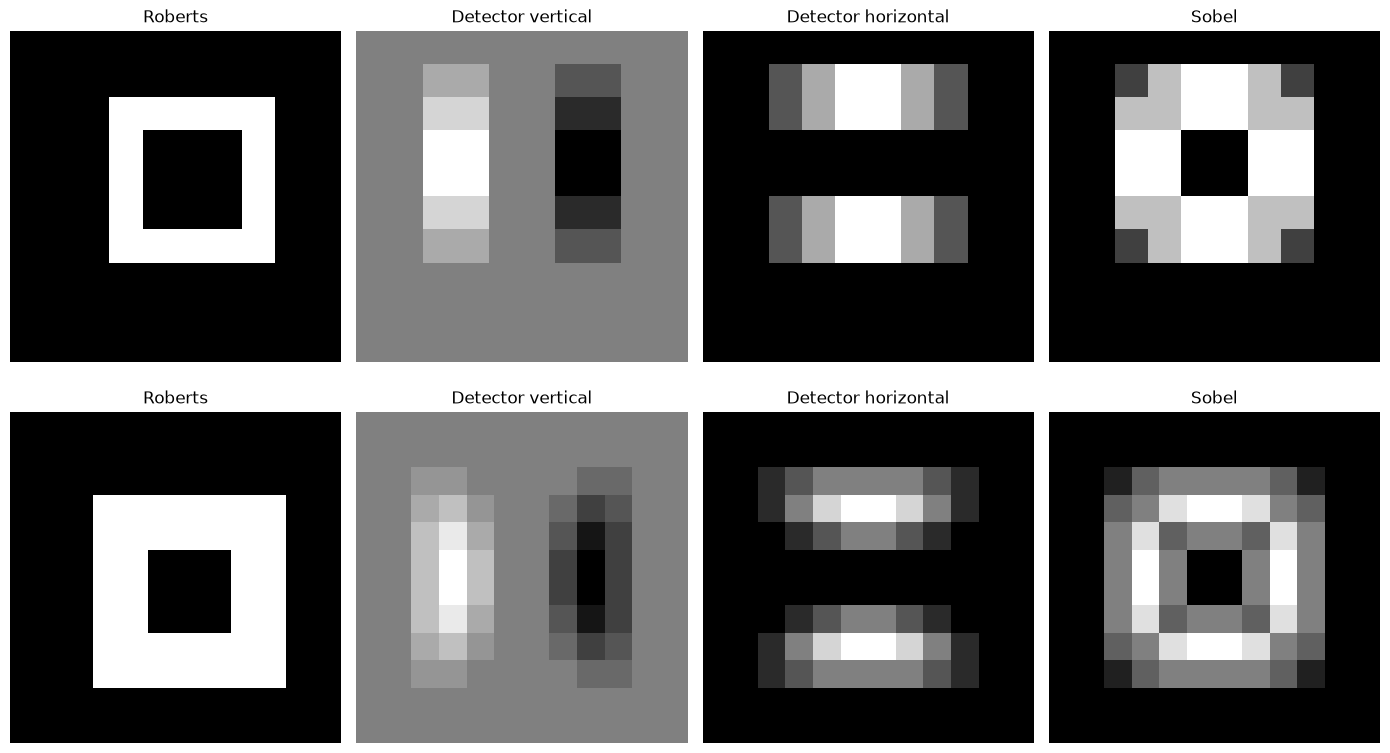

In [17]:
fig, ejes = plt.subplots(2, 4, figsize=(14, 8))

for i, (nombre, resultado) in enumerate(zip(nombres, resultados_1)):
    ejes[0, i].imshow(resultado, cmap="gray")
    ejes[0, i].set_title(nombre)
    ejes[0, i].axis("off")

for i, (nombre, resultado) in enumerate(zip(nombres, resultados_2)):
    ejes[1, i].imshow(resultado, cmap="gray")
    ejes[1, i].set_title(nombre)
    ejes[1, i].axis("off")

ejes[0, 0].set_ylabel("Imagen 1", fontsize=12)
ejes[1, 0].set_ylabel("Imagen 2", fontsize=12)

plt.tight_layout()

plt.savefig(
    "resultados/ejercicio_3/ejercicio_3_resultados.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Ejercicio 4. Aplicación y comparación de detectores de bordes

**Objetivo:** Aplicar los detectores Sobel, Canny, Prewitt y Roberts a las imágenes proporcionadas en la actividad, con el propósito de identificar los bordes y comparar el desempeño de cada algoritmo.

**Procedimiento:** Se cargarán las imágenes desde la carpeta `data/imagenes` y se procesarán individualmente mediante los cuatro detectores. Los resultados se visualizarán para comparar las características de los bordes identificados.

**Análisis:** Se determinará cuál detector ofrece el mejor resultado para cada imagen, teniendo en cuenta la claridad de los contornos, la continuidad de los bordes y la presencia de ruido.

In [18]:
import os

# Ruta de la carpeta que contiene las imágenes
carpeta_imagenes = "data/imagenes"

# Obtener los nombres de los archivos
archivos = os.listdir(carpeta_imagenes)

# Mostrar las imágenes encontradas
print("Cantidad de archivos:", len(archivos))

for archivo in archivos:
    print(archivo)

Cantidad de archivos: 11
2010_Mid-Hudson_balloon_festival_3.JPG
2024_Warszawa_plac_Politechniki,_Google_Street_View,_1.jpg
640px-FBI_Chicago_Agents faces.jpg
Beta_cell_processed.jpg
Car_in_San_Juan_Street.jpg
Cumilla_City_Night.jpg
New_York_and_Jersey_City_Skyline_Panorama city 2.jpg
Pink_American_Rose_(Unsplash).jpg
Sintetica.jpg
Sintetica2.jpg
Sintetica3.jpg


In [19]:
# Diccionario para almacenar las imágenes
imagenes = {}

# Recorrer todos los archivos de la carpeta
for archivo in archivos:

    # Construir la ruta completa de cada imagen
    ruta = os.path.join(carpeta_imagenes, archivo)

    # Leer la imagen en escala de grises
    imagen = cv2.imread(ruta, cv2.IMREAD_GRAYSCALE)

    # Comprobar que la imagen se haya cargado correctamente
    if imagen is not None:
        imagenes[archivo] = imagen
    else:
        print("No se pudo cargar:", archivo)

# Mostrar información de las imágenes cargadas
print("Imágenes cargadas correctamente:", len(imagenes))

for nombre, imagen in imagenes.items():
    print(nombre, "-> Dimensiones:", imagen.shape)

Imágenes cargadas correctamente: 11
2010_Mid-Hudson_balloon_festival_3.JPG -> Dimensiones: (428, 640)
2024_Warszawa_plac_Politechniki,_Google_Street_View,_1.jpg -> Dimensiones: (480, 640)
640px-FBI_Chicago_Agents faces.jpg -> Dimensiones: (844, 640)
Beta_cell_processed.jpg -> Dimensiones: (640, 640)
Car_in_San_Juan_Street.jpg -> Dimensiones: (369, 640)
Cumilla_City_Night.jpg -> Dimensiones: (427, 640)
New_York_and_Jersey_City_Skyline_Panorama city 2.jpg -> Dimensiones: (160, 640)
Pink_American_Rose_(Unsplash).jpg -> Dimensiones: (423, 640)
Sintetica.jpg -> Dimensiones: (256, 256)
Sintetica2.jpg -> Dimensiones: (220, 228)
Sintetica3.jpg -> Dimensiones: (173, 187)


In [20]:
# Máscaras del detector Prewitt
prewitt_x = np.array([
    [-1, 0, 1],
    [-1, 0, 1],
    [-1, 0, 1]
], dtype=np.float32)

prewitt_y = np.array([
    [-1, -1, -1],
    [ 0,  0,  0],
    [ 1,  1,  1]
], dtype=np.float32)

# Máscaras del detector Roberts
roberts_x = np.array([
    [1,  0],
    [0, -1]
], dtype=np.float32)

roberts_y = np.array([
    [ 0, 1],
    [-1, 0]
], dtype=np.float32)

In [21]:
def aplicar_detectores(imagen):

    # 1. Detector Sobel
    sobel_x = cv2.Sobel(imagen, cv2.CV_32F, 1, 0, ksize=3)
    sobel_y = cv2.Sobel(imagen, cv2.CV_32F, 0, 1, ksize=3)

    resultado_sobel = np.maximum(
        np.abs(sobel_x),
        np.abs(sobel_y)
    )

    # 2. Detector Canny
    resultado_canny = cv2.Canny(imagen, 100, 200)

    # 3. Detector Prewitt
    prewitt_gx = cv2.filter2D(imagen, cv2.CV_32F, prewitt_x)
    prewitt_gy = cv2.filter2D(imagen, cv2.CV_32F, prewitt_y)

    resultado_prewitt = np.maximum(
        np.abs(prewitt_gx),
        np.abs(prewitt_gy)
    )

    # 4. Detector Roberts
    roberts_gx = cv2.filter2D(imagen, cv2.CV_32F, roberts_x)
    roberts_gy = cv2.filter2D(imagen, cv2.CV_32F, roberts_y)

    resultado_roberts = np.maximum(
        np.abs(roberts_gx),
        np.abs(roberts_gy)
    )

    return {
        "Sobel": cv2.convertScaleAbs(resultado_sobel),
        "Canny": resultado_canny,
        "Prewitt": cv2.convertScaleAbs(resultado_prewitt),
        "Roberts": cv2.convertScaleAbs(resultado_roberts)
    }

In [22]:
# Diccionario para almacenar todos los resultados
resultados_ejercicio_4 = {}

# Recorrer las 11 imágenes
for nombre, imagen in imagenes.items():

    # Aplicar los cuatro detectores
    resultados = aplicar_detectores(imagen)

    # Guardar los resultados asociados al nombre original
    resultados_ejercicio_4[nombre] = resultados

print("Procesamiento terminado.")
print("Imágenes procesadas:", len(resultados_ejercicio_4))

Procesamiento terminado.
Imágenes procesadas: 11


In [23]:
def visualizar_resultados(nombre, imagen, resultados):

    fig, ejes = plt.subplots(1, 5, figsize=(18, 5))

    # Mostrar imagen original
    ejes[0].imshow(imagen, cmap="gray")
    ejes[0].set_title("Original")
    ejes[0].axis("off")

    # Mostrar resultados de los cuatro detectores
    for i, (detector, resultado) in enumerate(resultados.items()):

        ejes[i + 1].imshow(resultado, cmap="gray")
        ejes[i + 1].set_title(detector)
        ejes[i + 1].axis("off")

    fig.suptitle(nombre, fontsize=12)

    plt.tight_layout()
    plt.show()

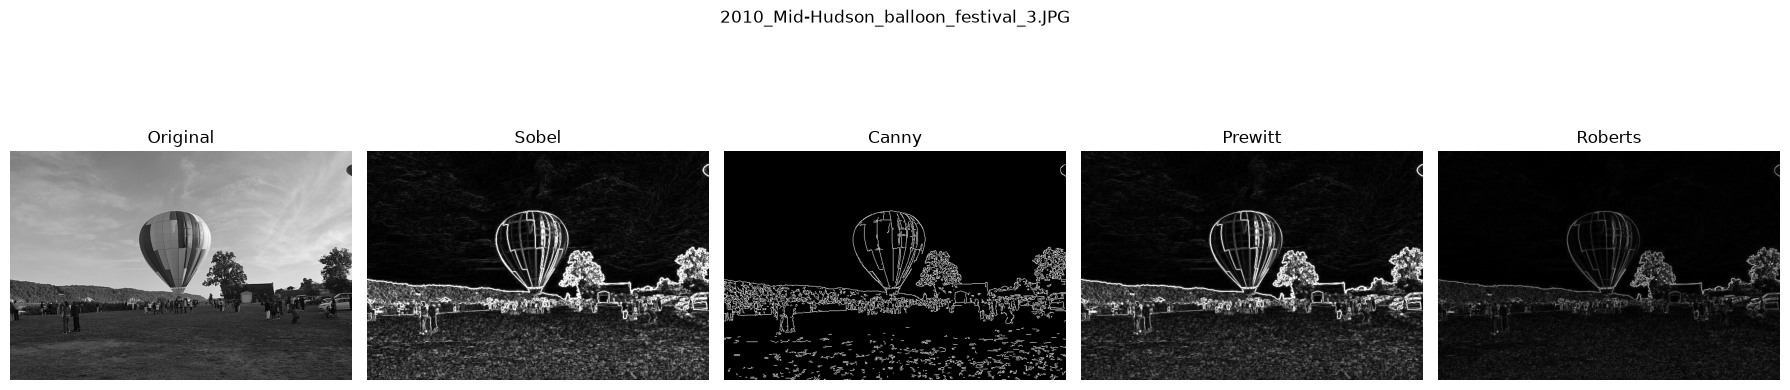

In [24]:
nombre = list(imagenes.keys())[0]

visualizar_resultados(
    nombre,
    imagenes[nombre],
    resultados_ejercicio_4[nombre]
)

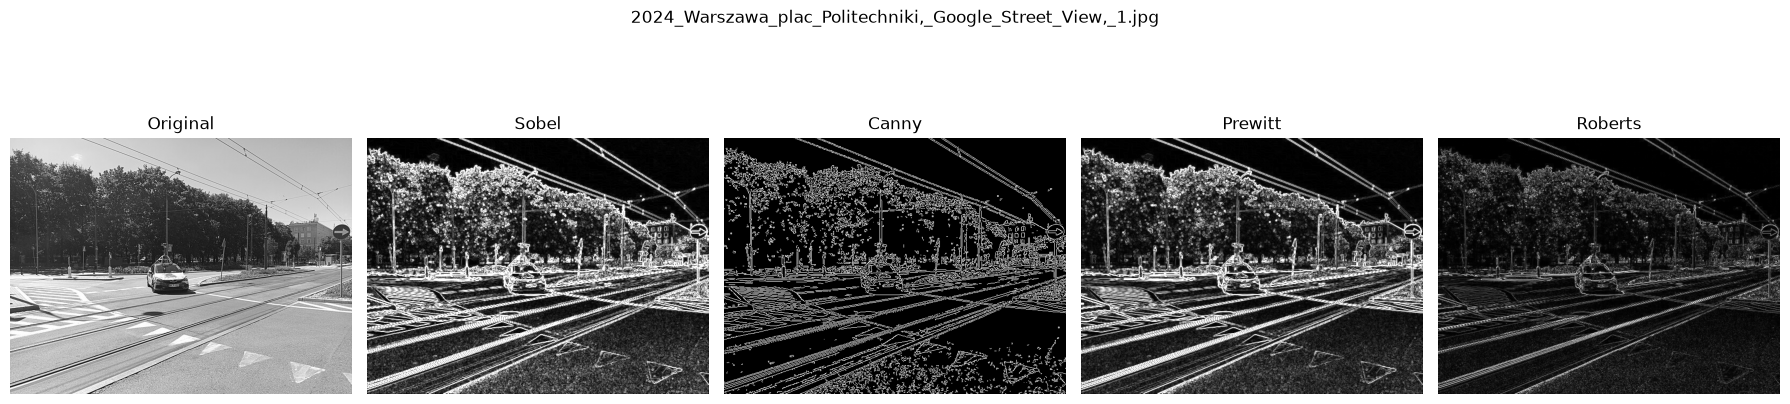

In [25]:
# Seleccionar la segunda imagen
nombre = list(imagenes.keys())[1]

# Mostrar la imagen original y los cuatro detectores
visualizar_resultados(
    nombre,
    imagenes[nombre],
    resultados_ejercicio_4[nombre]
)

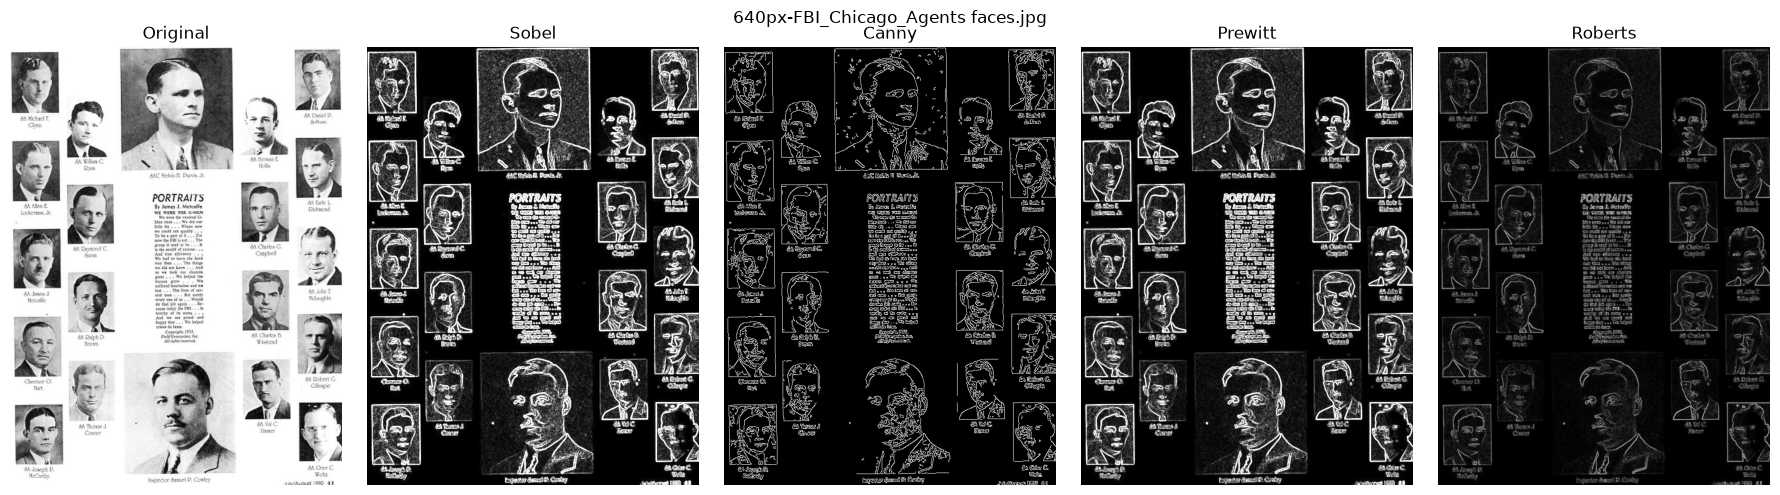

In [26]:
# Seleccionar la segunda imagen
nombre = list(imagenes.keys())[2]

# Mostrar la imagen original y los cuatro detectores
visualizar_resultados(
    nombre,
    imagenes[nombre],
    resultados_ejercicio_4[nombre]
)

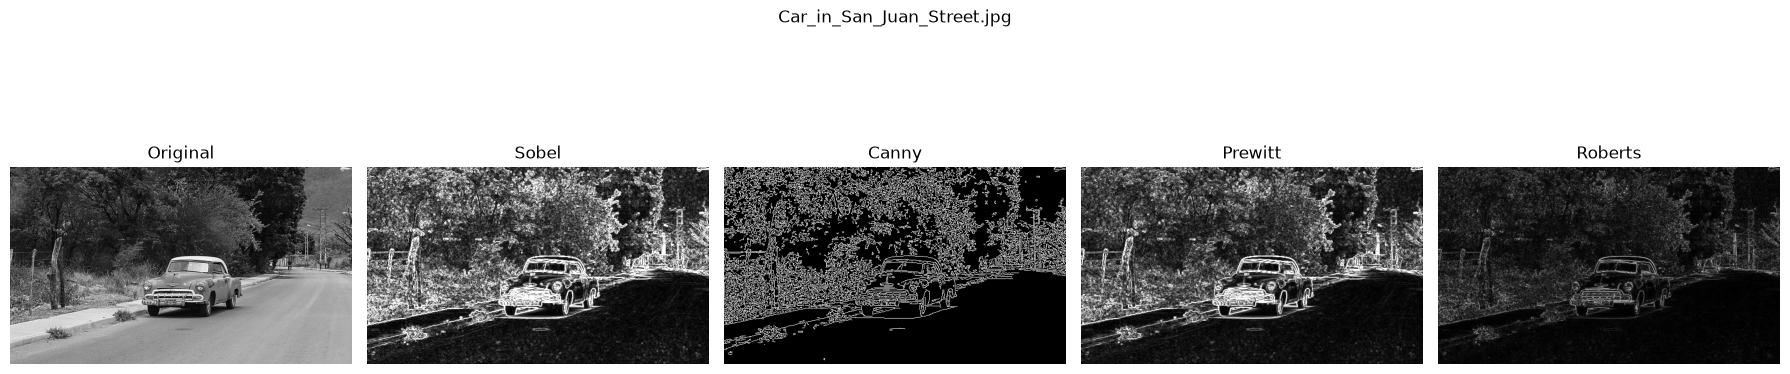

In [27]:
# Seleccionar la segunda imagen
nombre = list(imagenes.keys())[4]

# Mostrar la imagen original y los cuatro detectores
visualizar_resultados(
    nombre,
    imagenes[nombre],
    resultados_ejercicio_4[nombre]
)

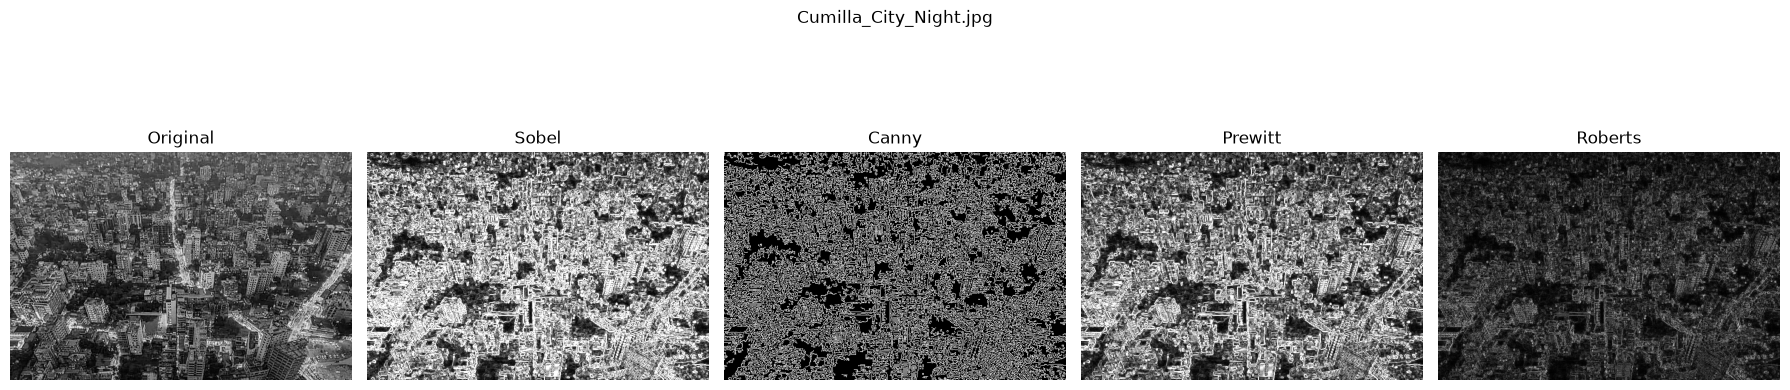

In [28]:
# Seleccionar la segunda imagen
nombre = list(imagenes.keys())[5]

# Mostrar la imagen original y los cuatro detectores
visualizar_resultados(
    nombre,
    imagenes[nombre],
    resultados_ejercicio_4[nombre]
)

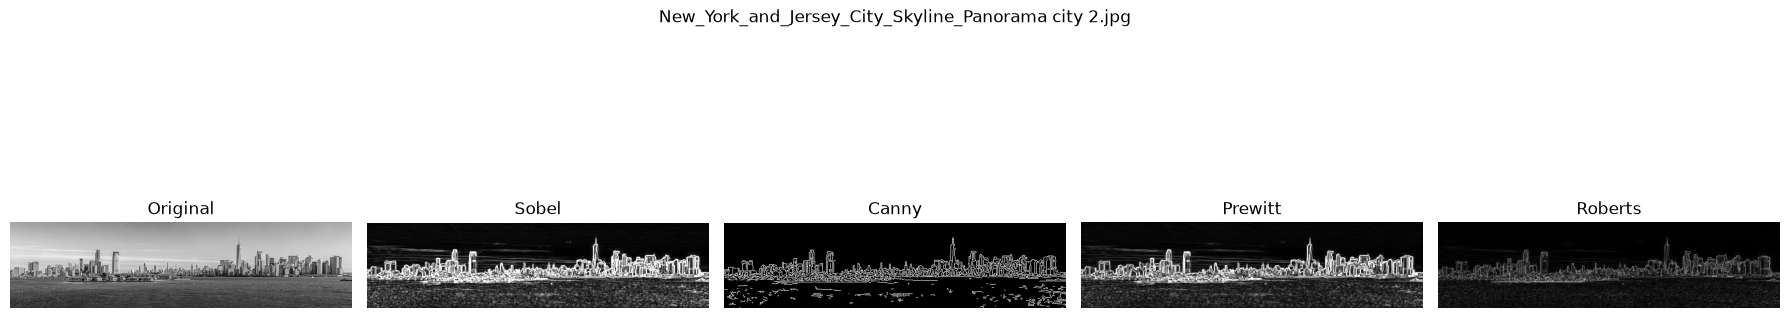

In [29]:
# Seleccionar la segunda imagen
nombre = list(imagenes.keys())[6]

# Mostrar la imagen original y los cuatro detectores
visualizar_resultados(
    nombre,
    imagenes[nombre],
    resultados_ejercicio_4[nombre]
)

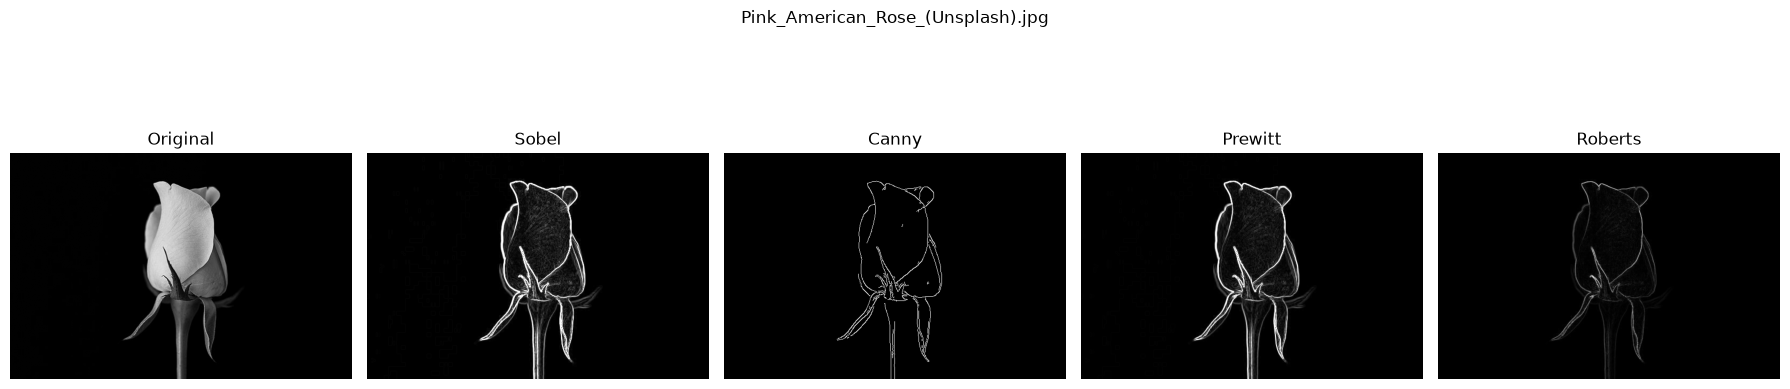

In [30]:
# Seleccionar la segunda imagen
nombre = list(imagenes.keys())[7]

# Mostrar la imagen original y los cuatro detectores
visualizar_resultados(
    nombre,
    imagenes[nombre],
    resultados_ejercicio_4[nombre]
)

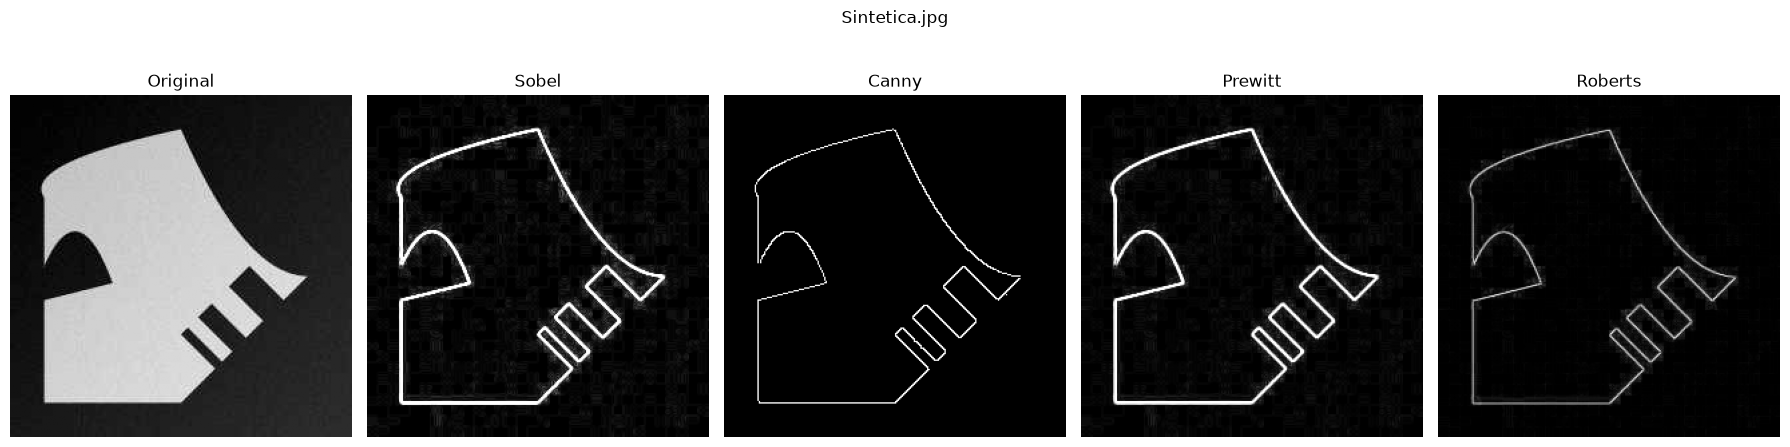

In [31]:
# Seleccionar la segunda imagen
nombre = list(imagenes.keys())[8]

# Mostrar la imagen original y los cuatro detectores
visualizar_resultados(
    nombre,
    imagenes[nombre],
    resultados_ejercicio_4[nombre]
)

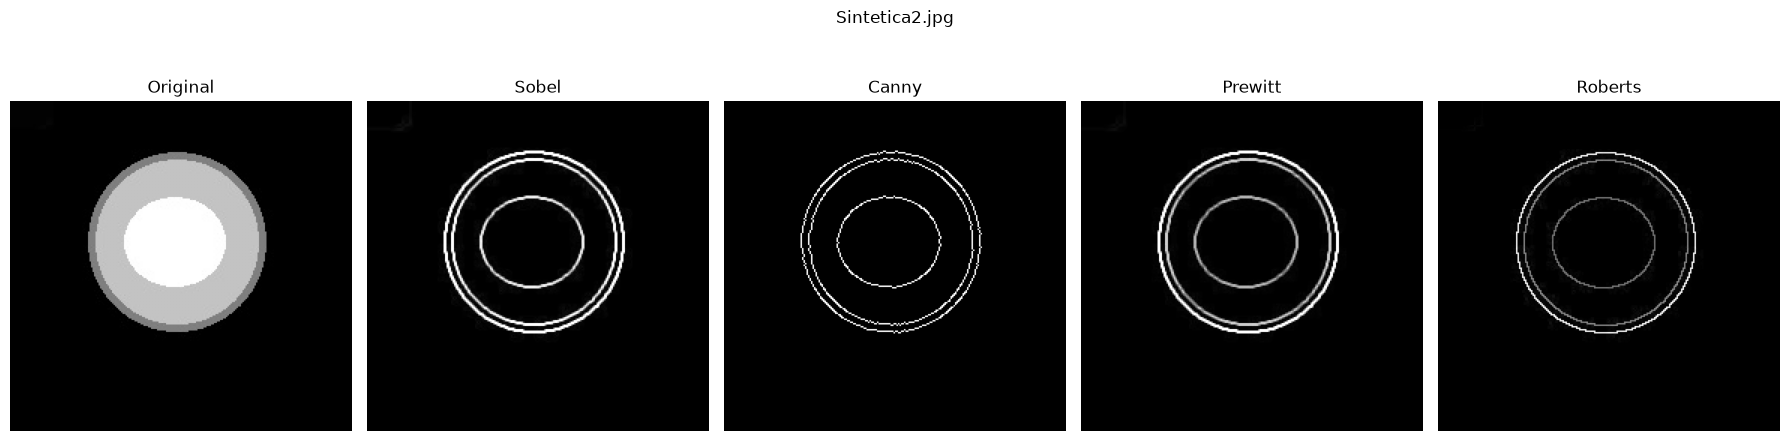

In [32]:
# Seleccionar la segunda imagen
nombre = list(imagenes.keys())[9]

# Mostrar la imagen original y los cuatro detectores
visualizar_resultados(
    nombre,
    imagenes[nombre],
    resultados_ejercicio_4[nombre]
)

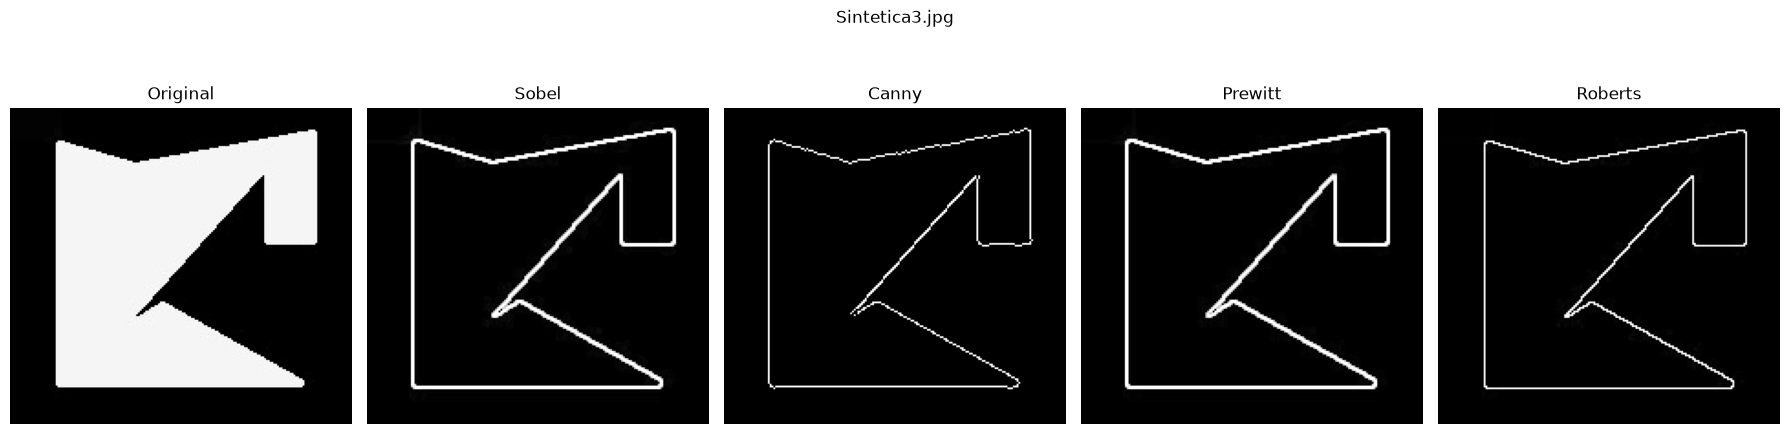

In [33]:
# Seleccionar la segunda imagen
nombre = list(imagenes.keys())[10]

# Mostrar la imagen original y los cuatro detectores
visualizar_resultados(
    nombre,
    imagenes[nombre],
    resultados_ejercicio_4[nombre]
)

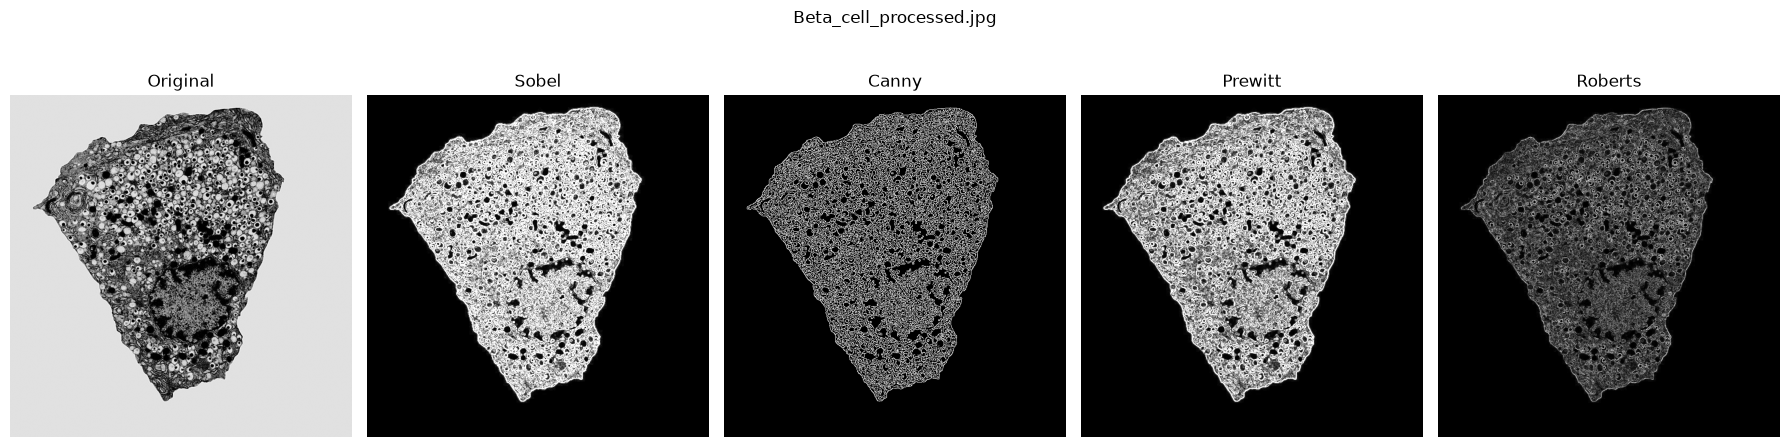

In [34]:
# Seleccionar la segunda imagen
nombre = list(imagenes.keys())[3]

# Mostrar la imagen original y los cuatro detectores
visualizar_resultados(
    nombre,
    imagenes[nombre],
    resultados_ejercicio_4[nombre]
)

In [35]:
# Crear la carpeta de resultados si no existe
carpeta_resultados = "resultados/ejercicio_4"
os.makedirs(carpeta_resultados, exist_ok=True)

# Recorrer todas las imágenes procesadas
for nombre, imagen in imagenes.items():

    # Obtener los resultados de los cuatro detectores
    resultados = resultados_ejercicio_4[nombre]

    # Crear una figura con cinco espacios
    fig, ejes = plt.subplots(1, 5, figsize=(18, 5))

    # Mostrar imagen original
    ejes[0].imshow(imagen, cmap="gray")
    ejes[0].set_title("Original")
    ejes[0].axis("off")

    # Mostrar los cuatro detectores
    for i, (detector, resultado) in enumerate(resultados.items()):
        ejes[i + 1].imshow(resultado, cmap="gray")
        ejes[i + 1].set_title(detector)
        ejes[i + 1].axis("off")

    # Añadir nombre de la imagen
    fig.suptitle(nombre, fontsize=12)

    plt.tight_layout()

    # Guardar la comparación
    nombre_salida = os.path.splitext(nombre)[0] + "_comparacion.png"
    ruta_salida = os.path.join(carpeta_resultados, nombre_salida)

    plt.savefig(ruta_salida, dpi=200, bbox_inches="tight")
    plt.close(fig)

print("Comparaciones guardadas:", len(resultados_ejercicio_4))

Comparaciones guardadas: 11
